# SMS Spam Classification using SVM
Dataset: https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset?resource=download

In [ ]:
# Install (if needed)
!pip -q install wordcloud nltk scikit-learn


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from wordcloud import WordCloud
import re, string, nltk
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score,classification_report,
confusion_matrix,ConfusionMatrixDisplay,
precision_score,recall_score,f1_score,roc_curve,auc)

nltk.download('stopwords')
nltk.download('wordnet')
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


## Upload dataset (`spam.csv`) downloaded from Kaggle.

In [ ]:
try:
    from google.colab import files
    uploaded = files.upload()
except ImportError:
    print('Not running in Colab - expecting spam.csv in the working directory')

Saving spam.csv to spam.csv


In [ ]:
df = pd.read_csv("spam.csv", encoding="latin-1")

df = df[['v1', 'v2']]

df.columns = ['label', 'message']

In [ ]:
print(df.shape)
print(df.info())
print(df.isnull().sum())
print("Duplicates:",df.duplicated().sum())
print(df['label'].value_counts())


(5572, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None
label      0
message    0
dtype: int64
Duplicates: 403
label
ham     4825
spam     747
Name: count, dtype: int64


## Exploratory Data Analysis

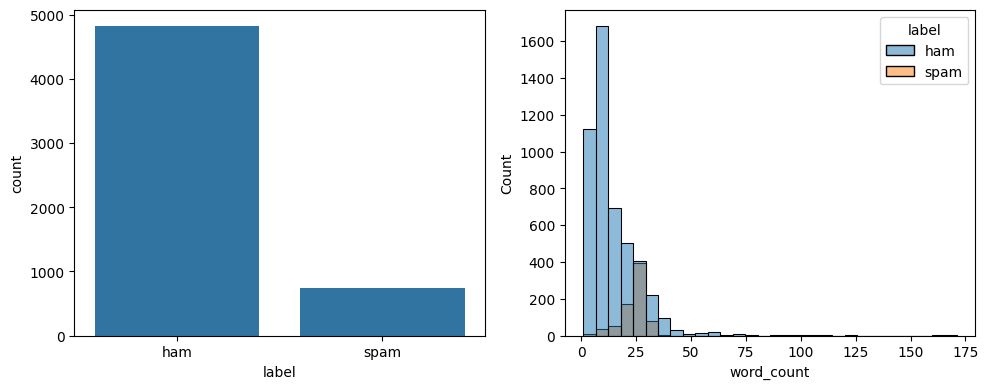

In [ ]:
df['char_count']=df['message'].str.len()
df['word_count']=df['message'].str.split().str.len()

fig,ax=plt.subplots(1,2,figsize=(10,4))
sns.countplot(data=df,x='label',ax=ax[0])
sns.histplot(data=df,x='word_count',hue='label',bins=30,ax=ax[1])
plt.tight_layout()
plt.show()




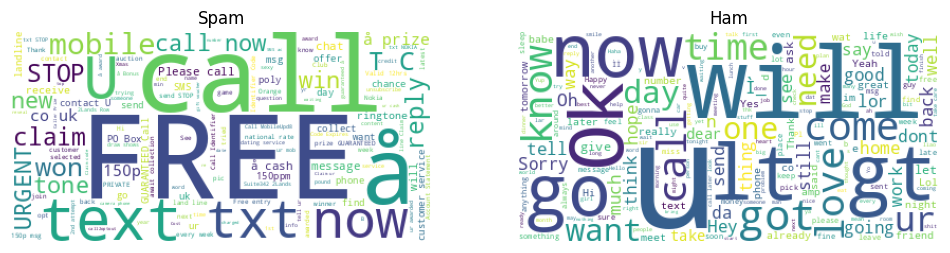

In [ ]:
spam=' '.join(df[df.label=='spam'].message)
ham=' '.join(df[df.label=='ham'].message)

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.imshow(WordCloud(background_color='white').generate(spam))
plt.axis('off'); plt.title("Spam")
plt.subplot(1,2,2)
plt.imshow(WordCloud(background_color='white').generate(ham))
plt.axis('off'); plt.title("Ham")
plt.show()


## Preprocessing

In [ ]:
# Load the list of English stopwords (e.g., "the", "is", "and")
stop_words = set(stopwords.words('english'))

# Create a WordNet lemmatizer object to convert words to their base form
lemm = WordNetLemmatizer()

# Define a function to clean and preprocess SMS text
def clean_text(text):

    # Convert all characters to lowercase
    text = text.lower()

    # Remove URLs (e.g., http://example.com or www.example.com)
    text = re.sub(r'http\S+|www\S+', ' ', text)

    # Remove email addresses (e.g., abc@gmail.com)
    text = re.sub(r'\S+@\S+', ' ', text)

    # Remove all numeric digits from the text
    text = re.sub(r'\d+', ' ', text)

    # Remove punctuation marks such as !, ?, ., ,, :, etc.
    text = text.translate(str.maketrans('', '', string.punctuation))

    # Split the sentence into words,
    # remove stopwords,
    # and convert each word to its base (lemma) form
    tokens = [
        lemm.lemmatize(word)
        for word in text.split()
        if word not in stop_words
    ]

    # Join the cleaned words back into a single string
    return ' '.join(tokens)

# Remove duplicate SMS messages from the dataset
df = df.drop_duplicates()

# Apply the clean_text() function to every message
# and store the cleaned text in a new column named 'clean_message'
df['clean_message'] = df['message'].apply(clean_text)

# Convert categorical labels into numerical values
# ham  -> 0
# spam -> 1
df['label'] = df['label'].map({
    'ham': 0,
    'spam': 1
})

# Display the first five rows of the processed dataset
df.head()

,label,message,char_count,word_count,clean_message
0,0,"Go until jurong point, crazy.. Available only ...",111,20,go jurong point crazy available bugis n great ...
1,0,Ok lar... Joking wif u oni...,29,6,ok lar joking wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,28,free entry wkly comp win fa cup final tkts st ...
3,0,U dun say so early hor... U c already then say...,49,11,u dun say early hor u c already say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,13,nah dont think go usf life around though


## Train/Test Split

In [ ]:
from sklearn.model_selection import train_test_split

X = df['clean_message']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)


(4135,)
(1034,)


## SVM Model

In [ ]:
pipeline=Pipeline([
('tfidf',TfidfVectorizer(max_features=5000,ngram_range=(1,2))),
('svm',LinearSVC())
])

pipeline.fit(X_train,y_train)
pred=pipeline.predict(X_test)

print("Accuracy:",accuracy_score(y_test,pred))
print("Precision:",precision_score(y_test,pred))
print("Recall:",recall_score(y_test,pred))
print("F1:",f1_score(y_test,pred))
print(classification_report(y_test,pred))




Accuracy: 0.9845261121856866
Precision: 0.9831932773109243
Recall: 0.8931297709923665
F1: 0.936
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       903
           1       0.98      0.89      0.94       131

    accuracy                           0.98      1034
   macro avg       0.98      0.95      0.96      1034
weighted avg       0.98      0.98      0.98      1034



## Hyperparameter Tuning

In [ ]:
param_grid={
'svm__C':[0.1,1,10]
}
grid=GridSearchCV(pipeline,param_grid,cv=5,n_jobs=-1)
grid.fit(X_train,y_train)

print("Best Parameters:",grid.best_params_)
print("Best CV Score:",grid.best_score_)


Best Parameters: {'svm__C': 1}
Best CV Score: 0.9787182587666263


## Cross Validation

In [ ]:
scores=cross_val_score(grid.best_estimator_,df['clean_message'],df['label'],cv=5)
print(scores)
print("Mean Accuracy:",scores.mean())


[0.98162476 0.9787234  0.98065764 0.98162476 0.97483059]
Mean Accuracy: 0.9794922302883003


## Prediction Function

In [ ]:
model=grid.best_estimator_

def predict_sms(text):
    pred=model.predict([clean_text(text)])[0]
    return "Spam" if pred==1 else "Ham"

print(predict_sms("Congratulations! You have won a free iPhone. Click here now."))
print(predict_sms("Hi, are we meeting tomorrow at 3 PM?"))


Spam
Ham


---
# Part 2 — Model comparison & going further

Part 1 built and tuned one model (TF-IDF + LinearSVC). Part 2 answers: *is that actually the best choice, and how far can it be pushed?*

| Section | What it does |
|---|---|
| 1 | Setup: shared split, evaluation helper, results store |
| 2 | Better features: raw text (keeps `!`, `£`, digits), char n-grams, hand-crafted features |
| 3 | Classical model comparison (SVM, LogReg, Naive Bayes, Random Forest, XGBoost, LightGBM) |
| 4 | Leaderboard, PR curves, confusion matrices |
| 5 | Threshold tuning (precision-first spam filtering), error analysis, top features |
| 6 | Sentence-embedding models |
| 7 | Fine-tuned DistilBERT |
| 8 | Explainability with LIME |
| 9 | Robustness: obfuscated spam (`fr33`, `w.i.n`), augmentation defence, modern-spam domain shift |
| 10 | Deployment: save the model, Gradio app |

> **Runtime:** sections 6-7 are much faster on a GPU (Colab: *Runtime → Change runtime type → T4 GPU*). Everything else runs on CPU.

In [ ]:
# Extra libraries for Part 2 (Colab already has torch / transformers / scikit-learn)
!pip -q install xgboost lightgbm sentence-transformers lime gradio

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 6.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


## 1. Setup: shared split, evaluation helper, results store

Every model is trained on the **same** training rows and scored once on the **same** held-out test rows, so the numbers are comparable.
The split reproduces Part 1 (same `random_state`, same stratification), but keeps the **raw** message so we can try features that Part 1's cleaning removed.

In [ ]:
import time, random, warnings
import joblib
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB, MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_recall_curve, average_precision_score,
                             roc_auc_score, fbeta_score)
warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# df was de-duplicated in Part 1; keep raw + cleaned text side by side
data = df[['message', 'clean_message', 'label']].copy()
train_df, test_df = train_test_split(data, test_size=0.20, random_state=SEED, stratify=data['label'])

# sanity check: identical split to Part 1
assert set(train_df.index) == set(X_train.index) and set(test_df.index) == set(X_test.index)

X_tr, X_te = train_df[['message']], test_df[['message']]      # raw text (DataFrame: feature builder selects 'message')
y_tr, y_te = train_df['label'].values, test_df['label'].values
pos_weight = (y_tr == 0).sum() / (y_tr == 1).sum()
print(f'train={len(train_df)}  test={len(test_df)}  spam share={y_tr.mean():.1%}  ham:spam ratio={pos_weight:.1f}')

train=4135  test=1034  spam share=12.6%  ham:spam ratio=6.9


In [ ]:
# ---- results store shared by every model in this notebook ----
results      = []   # one dict per model -> leaderboard
test_scores  = {}   # model -> continuous test scores (for PR / ROC curves)
test_preds   = {}   # model -> 0/1 test predictions (for confusion matrices)
predictors   = {}   # model -> function(list_of_texts) -> 0/1 array (used for robustness tests)

def evaluate(name, y_pred, y_score, family='', cv_f1=np.nan, fit_time=np.nan):
    row = dict(model=name, family=family,
               accuracy=accuracy_score(y_te, y_pred),
               precision=precision_score(y_te, y_pred),
               recall=recall_score(y_te, y_pred),
               f1=f1_score(y_te, y_pred),
               roc_auc=roc_auc_score(y_te, y_score),
               pr_auc=average_precision_score(y_te, y_score),
               cv_f1=cv_f1, fit_time_s=fit_time)
    results[:] = [r for r in results if r['model'] != name]    # re-running a cell replaces the row
    results.append(row)
    test_scores[name], test_preds[name] = np.asarray(y_score), np.asarray(y_pred)
    return row

# ---- Part 1 model as the baseline (cleaned text, no class weighting) ----
base = grid.best_estimator_
name = 'LinearSVC - Part 1 (cleaned text)'
evaluate(name, base.predict(test_df['clean_message']), base.decision_function(test_df['clean_message']),
         family='Part 1 baseline', cv_f1=np.nan)
predictors[name] = lambda texts, m=base: m.predict([clean_text(t) for t in texts])
pd.DataFrame(results).round(4)

,model,family,accuracy,precision,recall,f1,roc_auc,pr_auc,cv_f1,fit_time_s
0,LinearSVC - Part 1 (cleaned text),Part 1 baseline,0.9845,0.9832,0.8931,0.936,0.9958,0.9819,NaN,NaN


## 2. Better features

Part 1's `clean_text` deletes digits, punctuation and URLs, but in SMS spam those are *exactly* the giveaways (`£1000`, `CALL 0906...`, `!!!`, `www.`). The feature builder below keeps the raw text and combines three views of every message:

1. **Word TF-IDF** (1-2 grams) with a token pattern that keeps `£ $ € !` as tokens
2. **Character n-gram TF-IDF** (2-5, word-bounded), which is robust to misspellings and `txt`-speak
3. **Hand-crafted features**: length, digit count and ratio, uppercase ratio, number of `!` and `?`, has-URL, has-phone-number, has-currency, average word length, number of ALL-CAPS words

The code is written to a small module (`spam_features.py`) so the saved model can be loaded later (for the app) without this notebook.

In [ ]:
%%writefile spam_features.py
"""Feature engineering + scoring helpers for the SMS spam classifier."""
import re
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, MaxAbsScaler

FEATURE_NAMES = ['n_chars', 'n_words', 'n_digits', 'digit_ratio', 'upper_ratio', 'n_exclaim',
                 'n_question', 'has_url', 'has_long_number', 'has_currency', 'avg_word_len', 'n_caps_words']

_URL = re.compile(r'(http|www\.|\.com|\.co\.uk|\.net)', re.I)
_LONG_NUMBER = re.compile(r'\d{5,}')
_CURRENCY = re.compile(r'[£$€]|\b\d+\s?(p|pence|gbp)\b', re.I)


def to_frame(texts):
    """list[str] | str -> DataFrame with the 'message' column the pipeline expects."""
    if isinstance(texts, str):
        texts = [texts]
    return pd.DataFrame({'message': list(texts)})


def handcrafted(texts):
    rows = []
    for t in texts:
        t = str(t)
        words = t.split()
        letters = [c for c in t if c.isalpha()]
        n_digits = sum(c.isdigit() for c in t)
        rows.append([
            len(t), len(words), n_digits, n_digits / max(len(t), 1),
            sum(c.isupper() for c in letters) / max(len(letters), 1),
            t.count('!'), t.count('?'),
            int(bool(_URL.search(t))), int(bool(_LONG_NUMBER.search(t))), int(bool(_CURRENCY.search(t))),
            float(np.mean([len(w) for w in words])) if words else 0.0,
            sum(w.isupper() and len(w) > 1 for w in words),
        ])
    return np.array(rows, dtype=float)


def _hand_names(transformer, input_features):
    return np.array(FEATURE_NAMES, dtype=object)


def build_features(use_char=True, use_hand=True):
    """ColumnTransformer over the raw 'message' column. All outputs are non-negative (Naive Bayes friendly)."""
    parts = [('word', TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True,
                                      token_pattern=r"(?u)\b\w+\b|[£$€!]"), 'message')]
    if use_char:
        parts.append(('char', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), min_df=3,
                                              sublinear_tf=True, max_features=30000), 'message'))
    if use_hand:
        parts.append(('hand', Pipeline([('f', FunctionTransformer(handcrafted, feature_names_out=_hand_names)),
                                        ('scale', MaxAbsScaler())]), 'message'))
    return ColumnTransformer(parts)


def get_scores(est, X):
    """Continuous spam score: decision_function if available, else P(spam)."""
    if hasattr(est, 'decision_function'):
        return np.asarray(est.decision_function(X))
    return est.predict_proba(X)[:, 1]

Writing spam_features.py


In [ ]:
import importlib, spam_features
importlib.reload(spam_features)
from spam_features import build_features, to_frame, get_scores, handcrafted, FEATURE_NAMES

# quick look at the hand-crafted features: spam vs ham averages
hc = pd.DataFrame(handcrafted(train_df['message']), columns=FEATURE_NAMES)
hc['label'] = np.where(y_tr == 1, 'spam', 'ham')
hc.groupby('label').mean().T.round(2)

label,ham,spam
n_chars,69.90,137.97
n_words,14.03,23.64
n_digits,0.30,15.40
digit_ratio,0.00,0.11
upper_ratio,0.08,0.16
n_exclaim,0.18,0.69
n_question,0.29,0.27
has_url,0.00,0.20
has_long_number,0.00,0.76
has_currency,0.00,0.50


## 3. Classical model comparison

All models share the same feature builder (fit **inside** each CV fold, so there's no leakage) and are tuned with 5-fold stratified CV on the training set, optimising **F1 of the spam class** rather than accuracy (the data is ~87 % ham, so accuracy flatters everything). Class imbalance is handled with `class_weight` / `scale_pos_weight`. The test set is touched exactly once per model.

XGBoost and LightGBM are included if installed.

In [ ]:
candidates = {
    'LinearSVC':           (LinearSVC(class_weight='balanced'),
                            {'clf__C': [0.1, 0.3, 1, 3]}),
    'Logistic Regression': (LogisticRegression(class_weight='balanced', max_iter=3000),
                            {'clf__C': [1, 10, 30, 100]}),
    'Complement NB':       (ComplementNB(),   {'clf__alpha': [0.03, 0.1, 0.3, 1]}),
    'Multinomial NB':      (MultinomialNB(),  {'clf__alpha': [0.03, 0.1, 0.3, 1]}),
    'Random Forest':       (RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample',
                                                   n_jobs=1, random_state=SEED), {}),
}
try:
    from xgboost import XGBClassifier
    candidates['XGBoost'] = (XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.8,
                                           colsample_bytree=0.5, scale_pos_weight=pos_weight,
                                           eval_metric='logloss', n_jobs=1, random_state=SEED), {})
except ImportError:
    print('xgboost not installed - skipping')
try:
    from lightgbm import LGBMClassifier
    candidates['LightGBM'] = (LGBMClassifier(n_estimators=300, learning_rate=0.1, num_leaves=31,
                                             class_weight='balanced', n_jobs=1, random_state=SEED,
                                             verbose=-1), {})
except ImportError:
    print('lightgbm not installed - skipping')

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
fitted, cv_f1_of = {}, {}

for name, (est, param_grid) in candidates.items():
    pipe = Pipeline([('features', build_features()), ('clf', est)])
    gs = GridSearchCV(pipe, param_grid, scoring='f1', cv=cv, n_jobs=-1, refit=True)
    gs.fit(X_tr, y_tr)
    best = gs.best_estimator_
    fitted[name], cv_f1_of[name] = best, gs.best_score_
    evaluate(name, best.predict(X_te), get_scores(best, X_te), family='Classical (TF-IDF + features)',
             cv_f1=gs.best_score_, fit_time=gs.refit_time_)
    predictors[name] = lambda texts, m=best: m.predict(to_frame(texts))
    print(f'{name:22s} CV F1={gs.best_score_:.4f}  best params={gs.best_params_}')

LinearSVC              CV F1=0.9586  best params={'clf__C': 3}
Logistic Regression    CV F1=0.9562  best params={'clf__C': 100}
Complement NB          CV F1=0.9523  best params={'clf__alpha': 0.03}
Multinomial NB         CV F1=0.9593  best params={'clf__alpha': 0.1}
Random Forest          CV F1=0.9332  best params={}
XGBoost                CV F1=0.9398  best params={}
LightGBM               CV F1=0.9412  best params={}


## 4. Leaderboard and plots

`plot_comparison()` is reusable: it is called again at the end, after the embedding / transformer models have been added.

,model,family,accuracy,precision,recall,f1,roc_auc,pr_auc,cv_f1,fit_time_s
0,Complement NB,Classical (TF-IDF + features),0.9913,0.9692,0.9618,0.9655,0.9985,0.9919,0.9523,2.5
1,Multinomial NB,Classical (TF-IDF + features),0.9913,0.9766,0.9542,0.9653,0.9981,0.9907,0.9593,1.4
2,Logistic Regression,Classical (TF-IDF + features),0.9903,0.9919,0.9313,0.9606,0.9970,0.9879,0.9562,4.1
3,LinearSVC,Classical (TF-IDF + features),0.9903,1.0000,0.9237,0.9603,0.9972,0.9885,0.9586,3.2
4,XGBoost,Classical (TF-IDF + features),0.9894,0.9762,0.9389,0.9572,0.9971,0.9883,0.9398,53.2
5,LightGBM,Classical (TF-IDF + features),0.9884,0.9760,0.9313,0.9531,0.9977,0.9898,0.9412,16.4
6,LinearSVC - Part 1 (cleaned text),Part 1 baseline,0.9845,0.9832,0.8931,0.9360,0.9958,0.9819,-,-
7,Random Forest,Classical (TF-IDF + features),0.9845,1.0000,0.8779,0.9350,0.9970,0.9865,0.9332,9.3


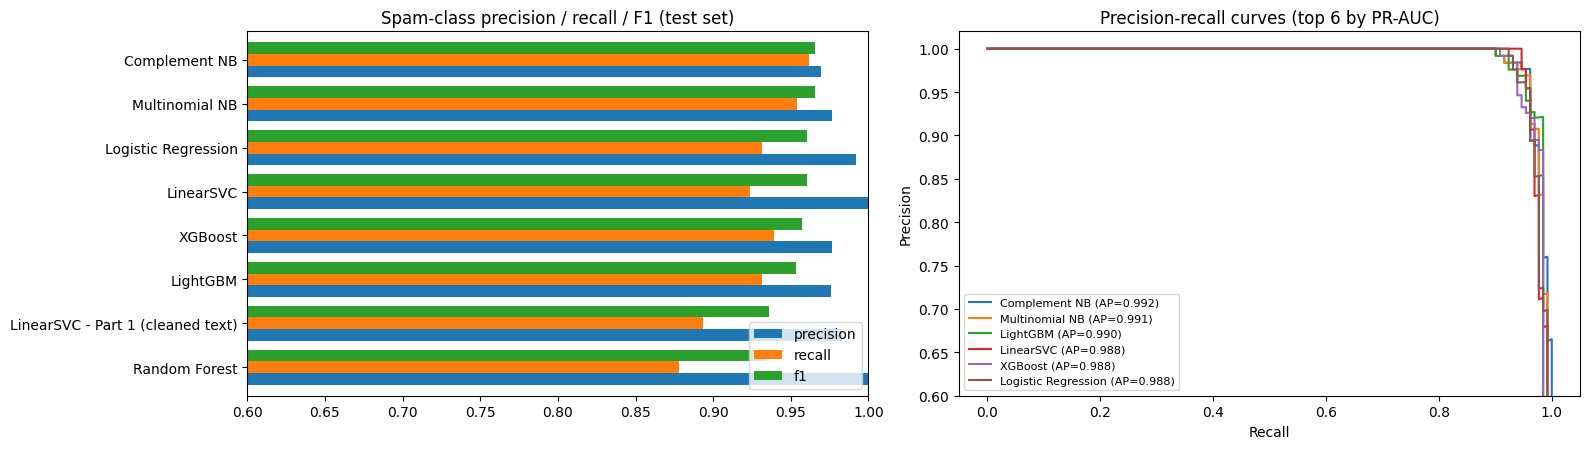

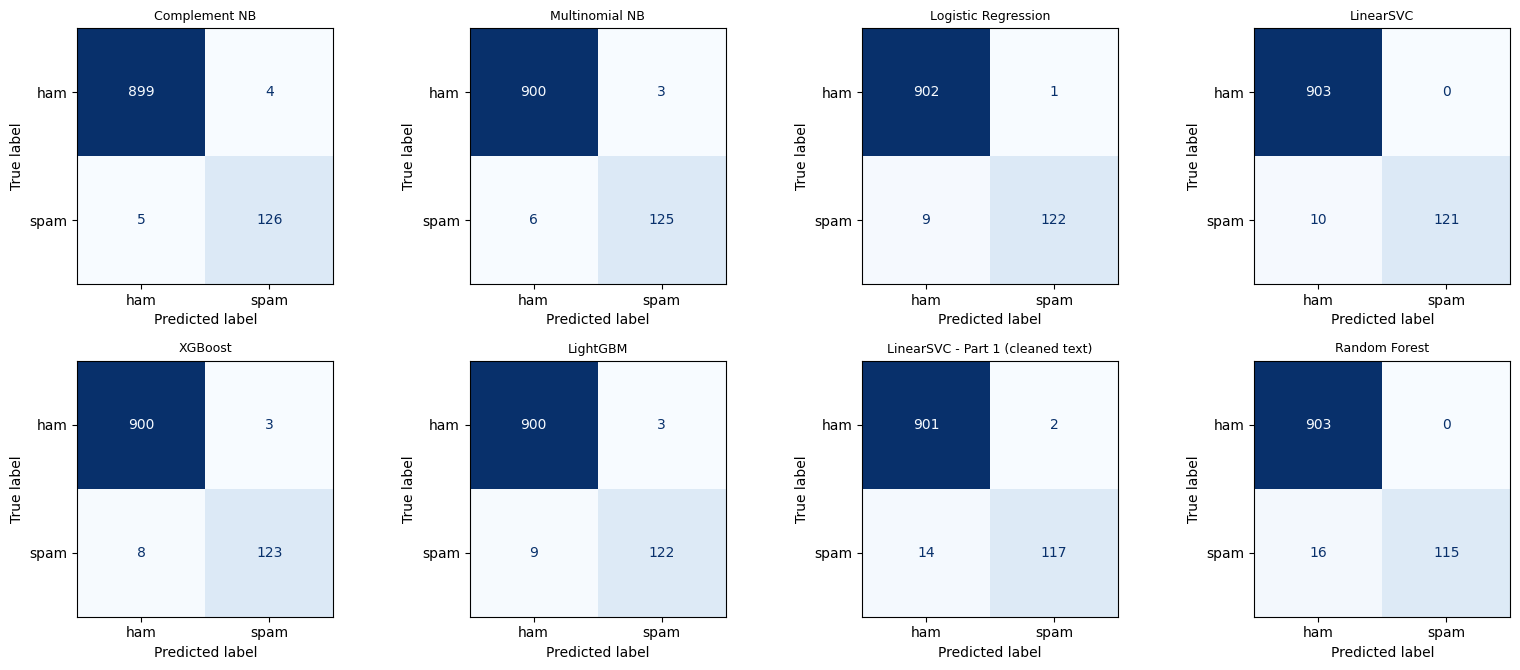

In [ ]:
def plot_comparison(top_pr=6):
    res = pd.DataFrame(results).sort_values('f1', ascending=False).reset_index(drop=True)
    cols = ['model', 'family', 'accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'pr_auc', 'cv_f1', 'fit_time_s']
    display(res[cols].style.format({c: '{:.4f}' for c in cols[2:9]} | {'fit_time_s': '{:.1f}'}, na_rep='-')
            .background_gradient(subset=['f1'], cmap='Greens'))

    fig, ax = plt.subplots(1, 2, figsize=(16, max(4, 0.45 * len(res) + 1)))
    res.set_index('model')[['precision', 'recall', 'f1']].iloc[::-1].plot.barh(ax=ax[0], width=0.8)
    ax[0].set_xlim(0.6, 1.0); ax[0].set_title('Spam-class precision / recall / F1 (test set)'); ax[0].set_ylabel('')
    for m in res.sort_values('pr_auc', ascending=False).head(top_pr)['model']:
        p, r, _ = precision_recall_curve(y_te, test_scores[m])
        ax[1].plot(r, p, label=f"{m} (AP={average_precision_score(y_te, test_scores[m]):.3f})")
    ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].set_ylim(0.6, 1.02)
    ax[1].set_title(f'Precision-recall curves (top {top_pr} by PR-AUC)'); ax[1].legend(fontsize=8, loc='lower left')
    plt.tight_layout(); plt.show()

    names = list(res['model'])
    ncols = 4; nrows = int(np.ceil(len(names) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.4 * nrows))
    for ax, m in zip(np.ravel(axes), names):
        ConfusionMatrixDisplay.from_predictions(y_te, test_preds[m], ax=ax, colorbar=False,
                                                display_labels=['ham', 'spam'], cmap='Blues')
        ax.set_title(m, fontsize=9)
    for ax in np.ravel(axes)[len(names):]:
        ax.axis('off')
    plt.tight_layout(); plt.show()
    return res

leaderboard = plot_comparison()

## 5. Threshold tuning, error analysis and top features

**Threshold tuning.** A spam filter that blocks a real message (false positive) is usually worse than letting one spam through. Instead of the default decision boundary we choose, using **out-of-fold predictions on the training set only**, the lowest threshold that keeps precision ≥ 99 %, which gives the highest recall subject to that constraint. The test set then shows what the choice really costs.

In [ ]:
TARGET_PRECISION = 0.99
best_name = max(cv_f1_of, key=cv_f1_of.get)            # chosen by CV on train - never by test score
best_est  = fitted[best_name]
print('Best classical model by CV F1:', best_name, f'({cv_f1_of[best_name]:.4f})')

method = 'decision_function' if hasattr(best_est, 'decision_function') else 'predict_proba'
oof = cross_val_predict(clone(best_est), X_tr, y_tr, cv=cv, method=method, n_jobs=-1)
oof = oof[:, 1] if method == 'predict_proba' else oof

prec, rec, thr_arr = precision_recall_curve(y_tr, oof)
ok = np.where(prec[:-1] >= TARGET_PRECISION)[0]
if len(ok):
    thr = thr_arr[ok[0]]
else:                                                   # fall back to the F1-optimal threshold
    f = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
    thr = thr_arr[f.argmax()]
print(f'Chosen threshold = {thr:.3f}  (target precision {TARGET_PRECISION:.0%} on out-of-fold predictions)')

scores = get_scores(best_est, X_te)
tuned_name = f'{best_name} (tuned threshold)'
evaluate(tuned_name, (scores >= thr).astype(int), scores, family='Classical + threshold',
         cv_f1=cv_f1_of[best_name])
predictors[tuned_name] = lambda texts, m=best_est, t=thr: (get_scores(m, to_frame(texts)) >= t).astype(int)

cmp = pd.DataFrame([r for r in results if r['model'] in (best_name, tuned_name)])
print(cmp[['model', 'precision', 'recall', 'f1']].round(4).to_string(index=False))
print(classification_report(y_te, (scores >= thr).astype(int), target_names=['ham', 'spam'], digits=3))

Best classical model by CV F1: Multinomial NB (0.9593)
Chosen threshold = 0.992  (target precision 99% on out-of-fold predictions)
                           model  precision  recall     f1
                  Multinomial NB     0.9766  0.9542 0.9653
Multinomial NB (tuned threshold)     0.9917  0.9160 0.9524
              precision    recall  f1-score   support

         ham      0.988     0.999     0.993       903
        spam      0.992     0.916     0.952       131

    accuracy                          0.988      1034
   macro avg      0.990     0.957     0.973      1034
weighted avg      0.988     0.988     0.988      1034



In [ ]:
# ---- Error analysis: which test messages does the (threshold-tuned) model get wrong? ----
pd.set_option('display.max_colwidth', 220)
pred_t = (scores >= thr).astype(int)
err = test_df.assign(pred=pred_t, score=scores)[lambda d: d['pred'] != d['label']]
fp = err[err['label'] == 0][['message', 'score']]          # ham flagged as spam
fn = err[err['label'] == 1][['message', 'score']]          # spam that slipped through
print(f'False positives (ham -> spam): {len(fp)}'); display(fp)
print(f'False negatives (spam -> ham): {len(fn)}'); display(fn)

False positives (ham -> spam): 1


,message,score
4860,Nokia phone is lovly..,0.998974


False negatives (spam -> ham): 11


,message,score
1506,Thanks for the Vote. Now sing along with the stars with Karaoke on your mobile. For a FREE link just reply with SING now.,0.775860
5098,"TheMob>Hit the link to get a premium Pink Panther game, the new no. 1 from Sugababes, a crazy Zebra animation or a badass Hoody wallpaper-all 4 FREE!",0.976315
671,SMS. ac sun0819 posts HELLO:\You seem cool,0.840678
2401,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about we go slo n hard! Txt XXX SLO(4msgs),0.000265
4819,Check Out Choose Your Babe Videos @ sms.shsex.netUN fgkslpoPW fgkslpo,0.990712
4142,"In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Day, C-Red Day. (Send A, B or C)",0.001753
4392,RECPT 1/3. You have ordered a Ringtone. Your order is being processed...,0.987425
3528,"Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & Sat night this week. They're selling fast!",0.013712
5449,"Latest News! Police station toilet stolen, cops have nothing to go on!",0.019535
1874,Would you like to see my XXX pics they are so hot they were nearly banned in the uk!,0.000041


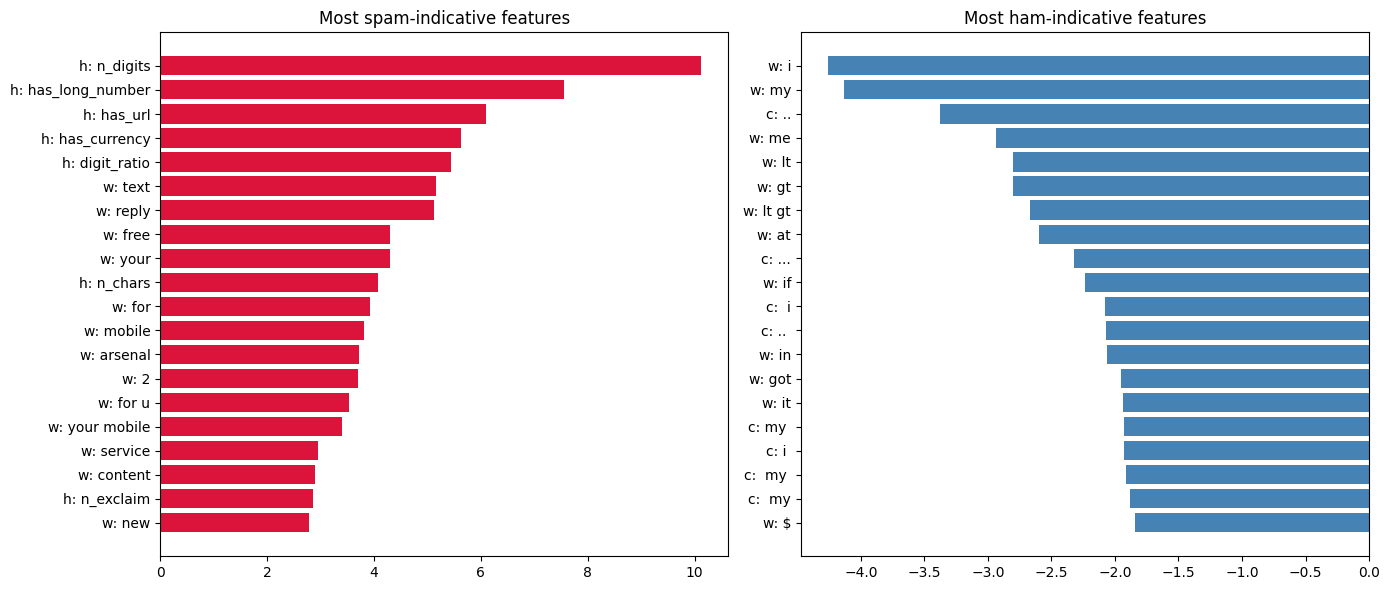

In [ ]:
# ---- Which features drive the decision? (Logistic Regression coefficients) ----
lr_pipe = fitted['Logistic Regression']
feat_names = lr_pipe.named_steps['features'].get_feature_names_out()
coef = lr_pipe.named_steps['clf'].coef_[0]
order = np.argsort(coef)
top_spam = [(feat_names[i], coef[i]) for i in order[::-1][:20]]
top_ham  = [(feat_names[i], coef[i]) for i in order[:20]]

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, items, title, color in [(ax[0], top_spam, 'Most spam-indicative features', 'crimson'),
                               (ax[1], top_ham,  'Most ham-indicative features',  'steelblue')]:
    names_, vals_ = zip(*items)
    a.barh([n.replace('word__', 'w: ').replace('char__', 'c: ').replace('hand__', 'h: ') for n in names_][::-1],
           vals_[::-1], color=color)
    a.set_title(title)
plt.tight_layout(); plt.show()